# Лабораторная работа 4. Кластеризация

Жойд Станислав Вадимович, группа 4417. Вариант задания 3.

Цель работы: изучить KMeans и агломеративную кластеризацию, подобрать число кластеров и сопоставить группы транзакций с известной меткой мошенничества.

Первая часть использует заданный генератор трёх групп. Для воспроизводимого эксперимента выбраны n=100 и seed=8. Во второй части исследуются транзакции электронной торговли. Fraud используется только для внешней оценки и не входит в признаки. Категориальные признаки описываются долями внутри кластеров, модели обучаются по пяти числовым признакам.

## Реализация расчётов

Генератор повторяет условие задания. StandardScaler вычитает среднее каждого признака и делит результат на стандартное отклонение. KMeans использует 20 инициализаций и random_state=8. Агломеративная модель использует метод Уорда. Коэффициент силуэта вычисляется по всем объектам, без случайной подвыборки.

In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score
from sklearn.metrics import fowlkes_mallows_score, homogeneity_score, completeness_score, v_measure_score
from sklearn.metrics import pairwise_distances



In [2]:
BASE = Path.cwd()
OUT = BASE / 'output'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})


def save_figure(name):
    plt.savefig(OUT / name, dpi=300, bbox_inches='tight')
    plt.close()


def make_data(n, seed):
    np.random.seed(seed)
    shift_matrix = np.array([[3, 3], [6, 9], [9, 3]])
    data = np.random.randn(3, 2, n) + shift_matrix.reshape((3, 2, 1))
    data = np.swapaxes(data, 1, 2)
    data = data.reshape((-1, 2))
    data *= np.array([[20, 0.5]])
    df = pd.DataFrame({'x': data[:, 0], 'y': data[:, 1]}, columns=['x', 'y'])
    return df.sample(frac=1.0)


def metrics(x, labels, target, distances):
    return {
        'silhouette': silhouette_score(distances, labels, metric='precomputed'),
        'calinski_harabasz': calinski_harabasz_score(x, labels),
        'davies_bouldin': davies_bouldin_score(x, labels),
        'ARI': adjusted_rand_score(target, labels),
        'AMI': adjusted_mutual_info_score(target, labels),
        'FMI': fowlkes_mallows_score(target, labels),
        'homogeneity': homogeneity_score(target, labels),
        'completeness': completeness_score(target, labels),
        'V_measure': v_measure_score(target, labels),
    }


def run():
    synthetic = make_data(100, 8)
    scaler = StandardScaler()
    x = scaler.fit_transform(synthetic)
    assert np.allclose(x.mean(axis=0), 0, atol=1e-12)
    assert np.allclose(x.std(axis=0), 1)
    synthetic_rows = []
    synthetic_labels = synthetic.copy()
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
    for ax, k in zip(axes, [2, 3, 4]):
        model = KMeans(n_clusters=k, n_init=20, random_state=8)
        labels = model.fit_predict(x)
        synthetic_labels[f'cluster_k{k}'] = labels
        centers = scaler.inverse_transform(model.cluster_centers_)
        ax.scatter(synthetic.x, synthetic.y, c=labels, cmap='tab10', s=10)
        ax.scatter(centers[:, 0], centers[:, 1], c='black', marker='X', s=90, label='Центры')
        ax.set(xlabel='x', ylabel='y', title=f'Число кластеров {k}')
        ax.legend(fontsize=8)
        synthetic_rows.append({'k': k, 'silhouette': silhouette_score(x, labels), 'inertia': model.inertia_})
    fig.tight_layout()
    save_figure('synthetic_clusters.png')
    synthetic_labels.to_csv(OUT / 'synthetic_labels.csv', index_label='source_row')
    pd.DataFrame(synthetic_rows).to_csv(OUT / 'synthetic_metrics.csv', index=False)
    synthetic_elbow = []
    for k in range(1, 11):
        model = KMeans(n_clusters=k, n_init=20, random_state=8).fit(x)
        synthetic_elbow.append({'k': k, 'inertia': model.inertia_})
    pd.DataFrame(synthetic_elbow).to_csv(OUT / 'synthetic_elbow.csv', index=False)
    plt.figure(figsize=(7, 4))
    plt.plot([r['k'] for r in synthetic_elbow], [r['inertia'] for r in synthetic_elbow], 'o-')
    plt.xticks(range(1, 11))
    plt.xlabel('Число кластеров')
    plt.ylabel('Сумма квадратов расстояний')
    plt.grid(alpha=.3)
    save_figure('synthetic_elbow.png')

    source = BASE / 'input' / 'ecommerce_fraud.csv'
    raw = pd.read_csv(source)
    numeric = ['transaction_amount', 'num_items', 'time_on_site_sec', 'hour_of_day', 'account_age_days']
    categorical = ['device_type', 'browser', 'payment_method', 'country', 'is_first_purchase', 'referral']
    audit = {
        'input_sha256': hashlib.sha256(source.read_bytes()).hexdigest(),
        'raw_rows': len(raw), 'columns': len(raw.columns),
        'missing': raw.isna().sum().to_dict(), 'duplicates': int(raw.duplicated().sum()),
        'numeric_features': numeric, 'categorical_features': categorical,
        'target_counts': raw.Fraud.value_counts().sort_index().to_dict(),
    }
    invalid = (raw.transaction_amount < 0) | (raw.time_on_site_sec < 0) | (raw.account_age_days < 0) | (~raw.num_items.between(1, 7)) | (~raw.hour_of_day.between(0, 23))
    raw.loc[invalid].to_csv(OUT / 'rejected_rows.csv', index_label='source_row')
    audit['invalid_rows'] = int(invalid.sum())
    audit['negative_amount_rows'] = int((raw.transaction_amount < 0).sum())
    audit['negative_time_rows'] = int((raw.time_on_site_sec < 0).sum())
    audit['negative_amount_and_time_rows'] = int(((raw.transaction_amount < 0) & (raw.time_on_site_sec < 0)).sum())
    audit['whitespace_categories'] = {column: int(raw[column].ne(raw[column].str.strip()).sum()) for column in categorical}
    data = raw.loc[~invalid].drop_duplicates().copy()
    audit['clean_target_counts'] = data.Fraud.value_counts().sort_index().to_dict()
    assert data[numeric + categorical + ['Fraud']].notna().all().all()
    assert set(data.Fraud.unique()) == {0, 1}
    assert (data[['transaction_amount', 'time_on_site_sec', 'account_age_days']] >= 0).all().all()
    assert data.num_items.between(1, 7).all()
    assert data.hour_of_day.between(0, 23).all()
    data[numeric].describe().to_csv(OUT / 'descriptive_statistics.csv')
    data.to_csv(OUT / 'clean_data.csv', index=False)
    audit['clean_rows'] = len(data)
    labels_ru = ['Сумма, USD', 'Число товаров', 'Время, с', 'Час суток', 'Возраст аккаунта, дней']
    fig, axes = plt.subplots(5, 5, figsize=(13, 13))
    colors = ['#2374ab', '#e4572e']
    for i, col_y in enumerate(numeric):
        for j, col_x in enumerate(numeric):
            ax = axes[i, j]
            for target, color in enumerate(colors):
                subset = data[data.Fraud == target]
                if i == j:
                    ax.hist(subset[col_x], bins=24, color=color, alpha=.5, density=True)
                else:
                    ax.scatter(subset[col_x], subset[col_y], color=color, alpha=.25, s=3, rasterized=True)
            ax.tick_params(labelsize=7)
            if i == 4:
                ax.set_xlabel(labels_ru[j], fontsize=9)
            if j == 0:
                ax.set_ylabel(labels_ru[i], fontsize=9)
    fig.suptitle('Синий: обычная транзакция; оранжевый: мошенническая', fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, .97))
    save_figure('scatter_matrix.png')
    scaler = StandardScaler()
    x = scaler.fit_transform(data[numeric])
    assert 'Fraud' not in numeric
    assert np.allclose(x.mean(axis=0), 0, atol=1e-12)
    assert np.allclose(x.std(axis=0), 1)
    pd.DataFrame({'feature': numeric, 'mean': scaler.mean_, 'scale': scaler.scale_}).to_csv(OUT / 'scaler.csv', index=False)
    distances = pairwise_distances(x)
    np.fill_diagonal(distances, 0)
    models = {}
    rows = []
    for method in ['KMeans', 'Ward']:
        for k in range(2, 11):
            model = (KMeans(n_clusters=k, n_init=20, random_state=8) if method == 'KMeans'
                     else AgglomerativeClustering(n_clusters=k, linkage='ward'))
            labels = model.fit_predict(x)
            models[(method, k)] = labels
            row = {'method': method, 'k': k, **metrics(x, labels, data.Fraud, distances)}
            row['inertia'] = model.inertia_ if method == 'KMeans' else np.nan
            rows.append(row)
    all_metrics = pd.DataFrame(rows)
    all_metrics.to_csv(OUT / 'model_selection.csv', index=False)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    km = all_metrics[all_metrics.method == 'KMeans']
    axes[0].plot(km.k, km.inertia, 'o-')
    axes[0].set(xlabel='Число кластеров', ylabel='Сумма квадратов расстояний', title='Метод локтя для KMeans')
    for method in ['KMeans', 'Ward']:
        sub = all_metrics[all_metrics.method == method]
        axes[1].plot(sub.k, sub.silhouette, 'o-', label=method)
    axes[1].set(xlabel='Число кластеров', ylabel='Коэффициент силуэта', title='Сравнение разбиений')
    axes[1].legend()
    for ax in axes:
        ax.set_xticks(range(2, 11))
        ax.grid(alpha=.3)
    fig.tight_layout()
    save_figure('model_selection.png')
    linked = linkage(x, method='ward')
    np.save(OUT / 'ward_linkage.npy', linked)
    pd.DataFrame(linked[-12:], columns=['left', 'right', 'distance', 'size']).to_csv(OUT / 'ward_last_merges.csv', index=False)
    plt.figure(figsize=(10, 5))
    dendrogram(linked, truncate_mode='lastp', p=20, show_leaf_counts=True, leaf_rotation=90, leaf_font_size=9, color_threshold=50)
    plt.axhline(50, color='black', linestyle='--', linewidth=1, label='Срез для трёх кластеров')
    plt.legend(fontsize=9)
    plt.xlabel('Объединённые группы, в скобках число объектов')
    plt.ylabel('Расстояние Уорда')
    plt.title('Дендрограмма всех транзакций, последние 20 групп')
    save_figure('dendrogram.png')
    selected = {}
    combined_labels = data.copy()
    for method in ['KMeans', 'Ward']:
        sub = all_metrics[all_metrics.method == method]
        best = sub.loc[sub.silhouette.idxmax()]
        k = int(best.k)
        selected[method] = {'k': k, **{key: float(best[key]) for key in metrics(x, models[(method, k)], data.Fraud, distances)}}
        labels = models[(method, k)]
        combined_labels[f'cluster_{method}'] = labels
        profile = data.assign(cluster=labels).groupby('cluster')[numeric + ['Fraud']].mean()
        profile.insert(0, 'size', pd.Series(labels).value_counts().sort_index())
        profile.to_csv(OUT / f'{method.lower()}_profiles.csv')
        pd.crosstab(labels, data.Fraud).to_csv(OUT / f'{method.lower()}_target_counts.csv')
        shares = []
        for feature in categorical:
            for cluster in range(k):
                for category, share in data.loc[labels == cluster, feature].value_counts(normalize=True).sort_index().items():
                    shares.append({'cluster': cluster, 'feature': feature, 'category': category, 'share': share})
        pd.DataFrame(shares).to_csv(OUT / f'{method.lower()}_category_shares.csv', index=False)
    combined_labels.to_csv(OUT / 'cluster_assignments.csv', index_label='source_row')
    audit['selected'] = selected
    audit['synthetic'] = {'n_per_group': 100, 'seed': 8, 'rows': len(synthetic), 'metrics': synthetic_rows}
    audit['numeric_ranges'] = {key: {'min': float(data[key].min()), 'max': float(data[key].max())} for key in numeric}
    (OUT / 'results.json').write_text(json.dumps(audit, ensure_ascii=False, indent=2), encoding='utf-8')
    summary = pd.DataFrame(selected).T.reset_index(names='Метод')
    prep = pd.DataFrame({'Проверка': ['Исходные строки', 'Пропуски', 'Дубликаты', 'Отрицательная сумма', 'Отрицательное время', 'Пересечение причин', 'После очистки', 'Fraud после очистки'], 'Количество': [len(raw), int(raw.isna().sum().sum()), int(raw.duplicated().sum()), audit['negative_amount_rows'], audit['negative_time_rows'], audit['negative_amount_and_time_rows'], len(data), int(data.Fraud.sum())]})
    html = '<!doctype html><html lang="ru"><meta charset="utf-8"><title>ЛР4. Результаты расчётов</title><style>body{font:18px Arial;margin:24px;color:#202124}section{margin-bottom:50px}table{border-collapse:collapse;font-size:16px}th,td{padding:8px 12px;border:1px solid #aaa;text-align:right}th{background:#eee}h1{font-size:26px}h2{font-size:23px}</style><h1>ЛР4. Результаты выполненных расчётов</h1>'
    html += '<section id="preprocessing"><h2>Проверка данных</h2>' + prep.to_html(index=False) + '</section>'
    html += '<section id="synthetic"><h2>Синтетические данные, n=100, seed=8</h2>' + pd.DataFrame(synthetic_rows).round(6).to_html(index=False) + '</section>'
    html += '<section id="comparison"><h2>Выбранные разбиения транзакций</h2>' + summary[['Метод', 'k', 'silhouette', 'calinski_harabasz', 'davies_bouldin', 'ARI', 'AMI']].round(6).to_html(index=False) + '</section>'
    for method in ['kmeans', 'ward']:
        profile = pd.read_csv(OUT / f'{method}_profiles.csv').rename(columns={'cluster':'Кластер','size':'Число','transaction_amount':'Сумма USD','num_items':'Товары','time_on_site_sec':'Время с','hour_of_day':'Час','account_age_days':'Возраст дней','Fraud':'Доля Fraud'})
        html += f'<section id="{method}"><h2>Профили {method}</h2>' + profile.round(4).to_html(index=False) + '</section>'
    html += '</html>'
    (OUT / 'results.html').write_text(html, encoding='utf-8')
    print(json.dumps(audit, ensure_ascii=False, indent=2))
    print(all_metrics.to_string(index=False))
    for method in ['kmeans', 'ward']:
        print(method)
        print(pd.read_csv(OUT / f'{method}_profiles.csv').to_string(index=False))
    assert len(combined_labels) == len(data)
    assert len(rows) == 18
    assert len(linked) == len(data) - 1
    assert all((OUT / name).exists() for name in ['synthetic_clusters.png', 'synthetic_elbow.png', 'scatter_matrix.png', 'model_selection.png', 'dendrogram.png'])




In [3]:
run()

{
  "input_sha256": "103520f510f54b4bc31121a5feaac63b09201cb7a78476dd77f7f7a92bbe5911",
  "raw_rows": 3024,
  "columns": 12,
  "missing": {
    "transaction_amount": 0,
    "device_type": 0,
    "browser": 0,
    "payment_method": 0,
    "country": 0,
    "num_items": 0,
    "time_on_site_sec": 0,
    "is_first_purchase": 0,
    "referral": 0,
    "hour_of_day": 0,
    "account_age_days": 0,
    "Fraud": 0
  },
  "duplicates": 0,
  "numeric_features": [
    "transaction_amount",
    "num_items",
    "time_on_site_sec",
    "hour_of_day",
    "account_age_days"
  ],
  "categorical_features": [
    "device_type",
    "browser",
    "payment_method",
    "country",
    "is_first_purchase",
    "referral"
  ],
  "target_counts": {
    "0": 2889,
    "1": 135
  },
  "invalid_rows": 154,
  "negative_amount_rows": 130,
  "negative_time_rows": 24,
  "negative_amount_and_time_rows": 0,
  "whitespace_categories": {
    "device_type": 0,
    "browser": 0,
    "payment_method": 0,
    "country": 0

## Часть 1. Синтетические группы

Сравниваются разбиения на 2, 3 и 4 кластера. Чёрные кресты обозначают центры, переведённые обратно в исходный масштаб признаков. Метод локтя использует сумму квадратов расстояний до ближайшего центра.

,k,silhouette,inertia
0,2,0.479072,336.934599
1,3,0.686977,82.440875
2,4,0.555488,70.614966


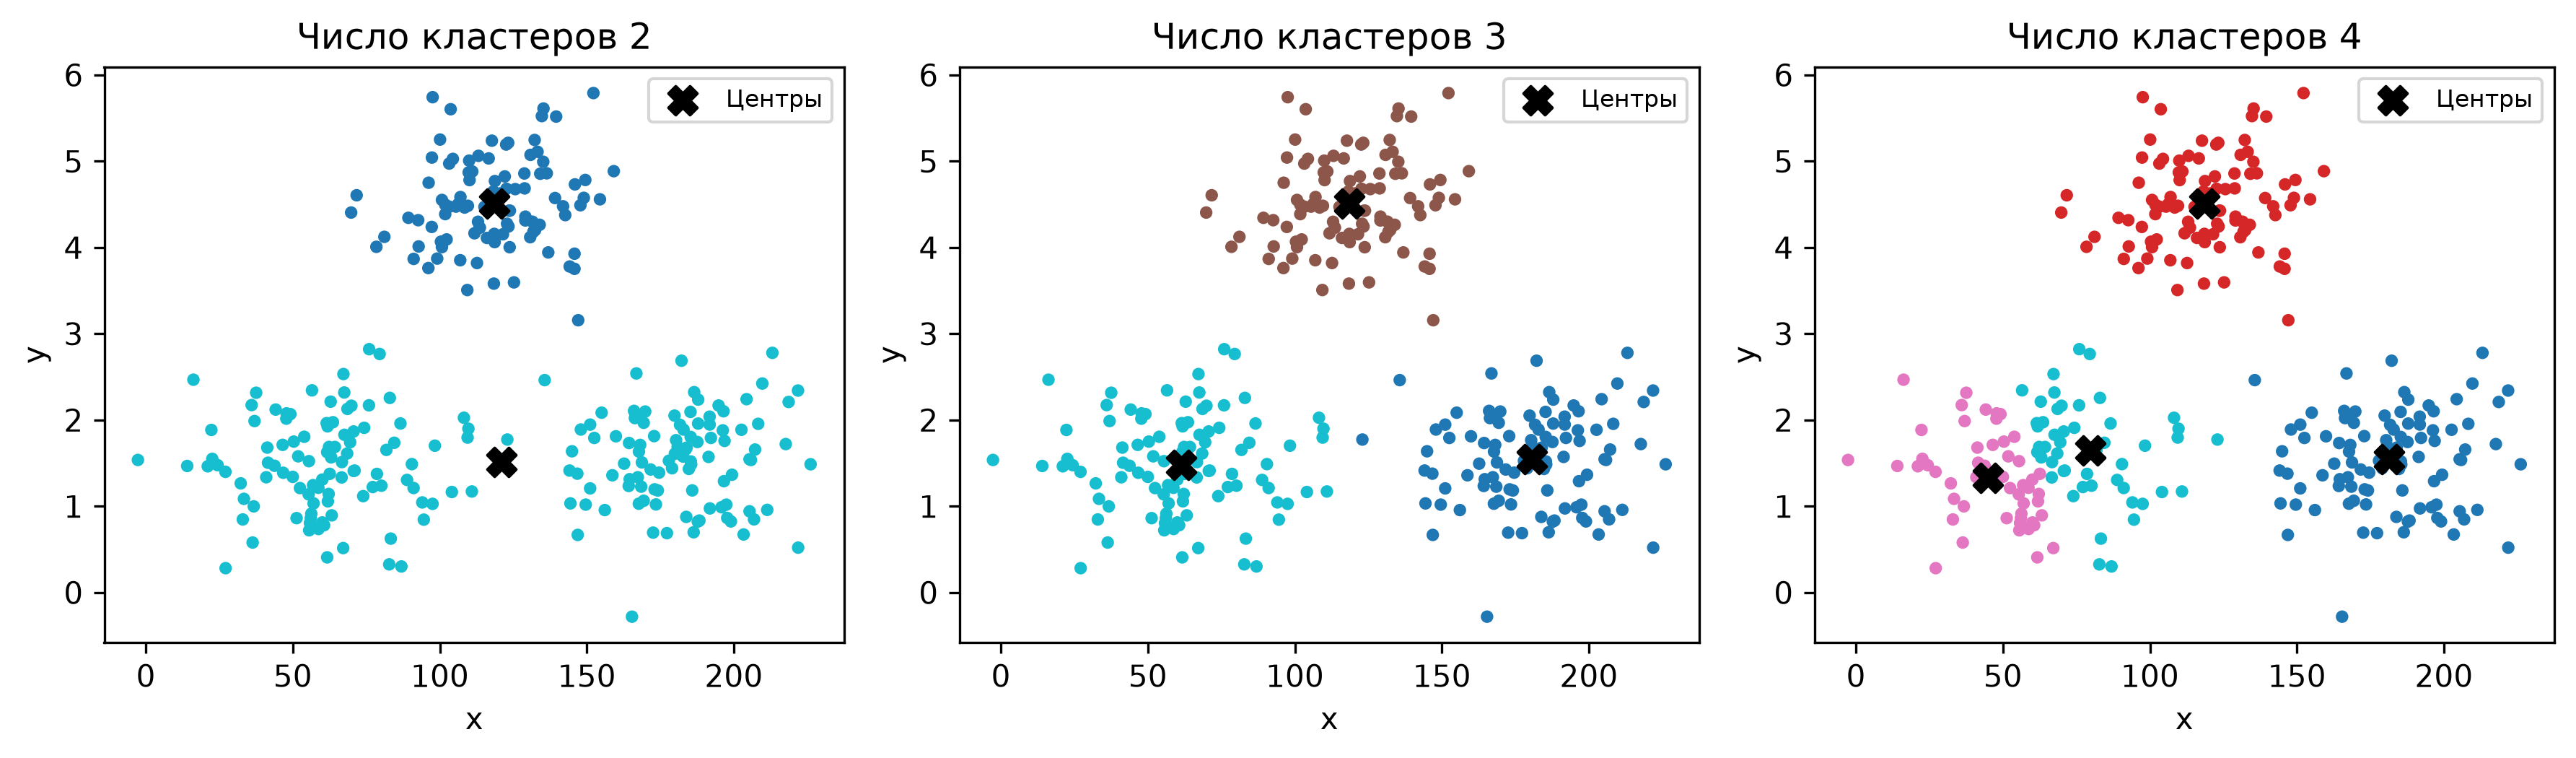

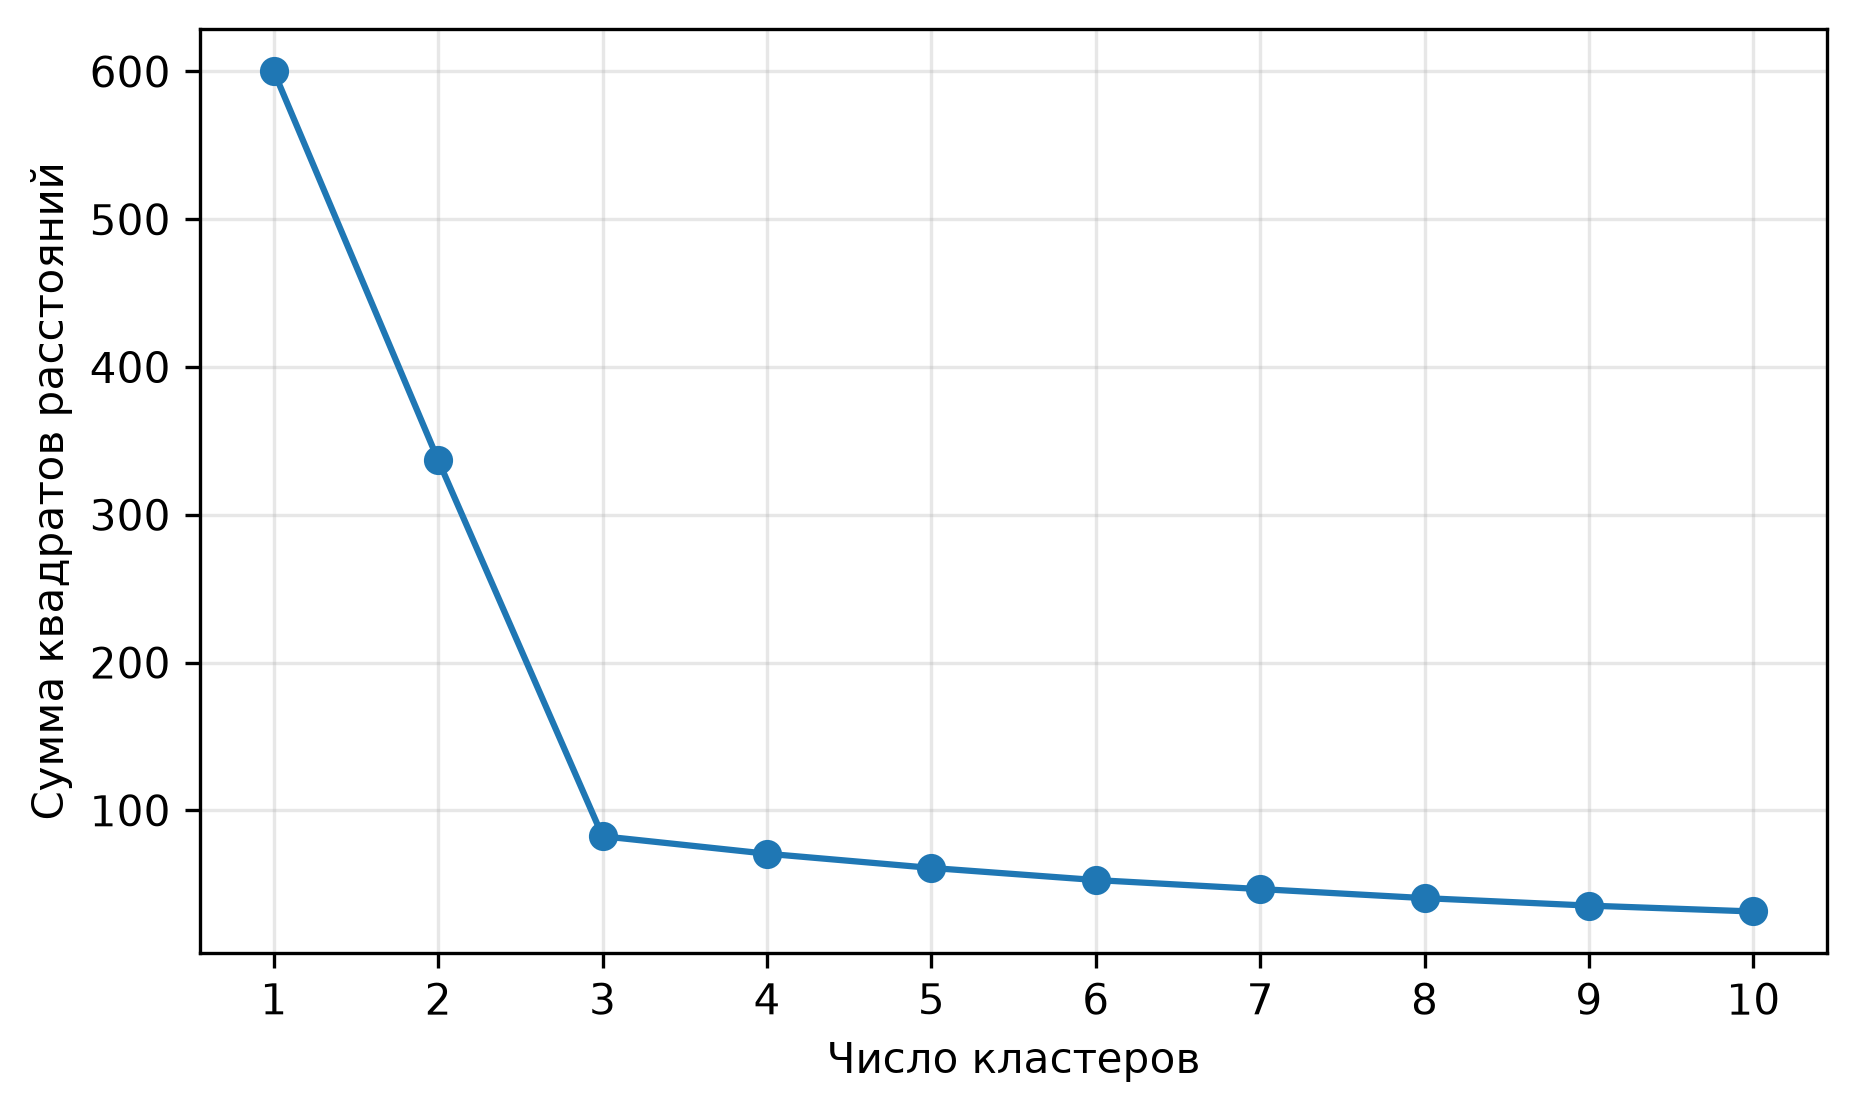

In [4]:
from IPython.display import display, Image
display(pd.read_csv(OUT / 'synthetic_metrics.csv'))
display(Image(filename=str(OUT / 'synthetic_clusters.png')))
display(Image(filename=str(OUT / 'synthetic_elbow.png')))

## Часть 2. Проверка и подготовка транзакций

Проверяются пропуски, дубликаты, пробелы в категориях, отрицательные суммы и время, допустимые диапазоны числа товаров и часа суток. Отрицательные суммы покупок и длительности сессий исключаются как некорректные значения. Крупные положительные суммы сохраняются. Матрица диаграмм показывает все пять числовых признаков; цвет соответствует Fraud.

,проверка,количество
0,Исходные строки,3024
1,Отрицательная сумма,130
2,Отрицательное время,24
3,Пересечение причин,0
4,Исключено строк,154
5,После очистки,2870


,transaction_amount,num_items,time_on_site_sec,hour_of_day,account_age_days
count,2870.000000,2870.000000,2870.000000,2870.000000,2870.000000
mean,84.991697,4.021254,165.043554,11.401742,921.931010
std,116.907696,1.991766,111.622012,6.910618,530.139562
min,0.010000,1.000000,0.000000,0.000000,2.000000
25%,20.082500,2.000000,83.000000,5.000000,457.000000
50%,47.770000,4.000000,142.000000,12.000000,935.000000
75%,101.857500,6.000000,218.750000,17.000000,1383.000000
max,1433.310000,7.000000,902.000000,23.000000,1823.000000


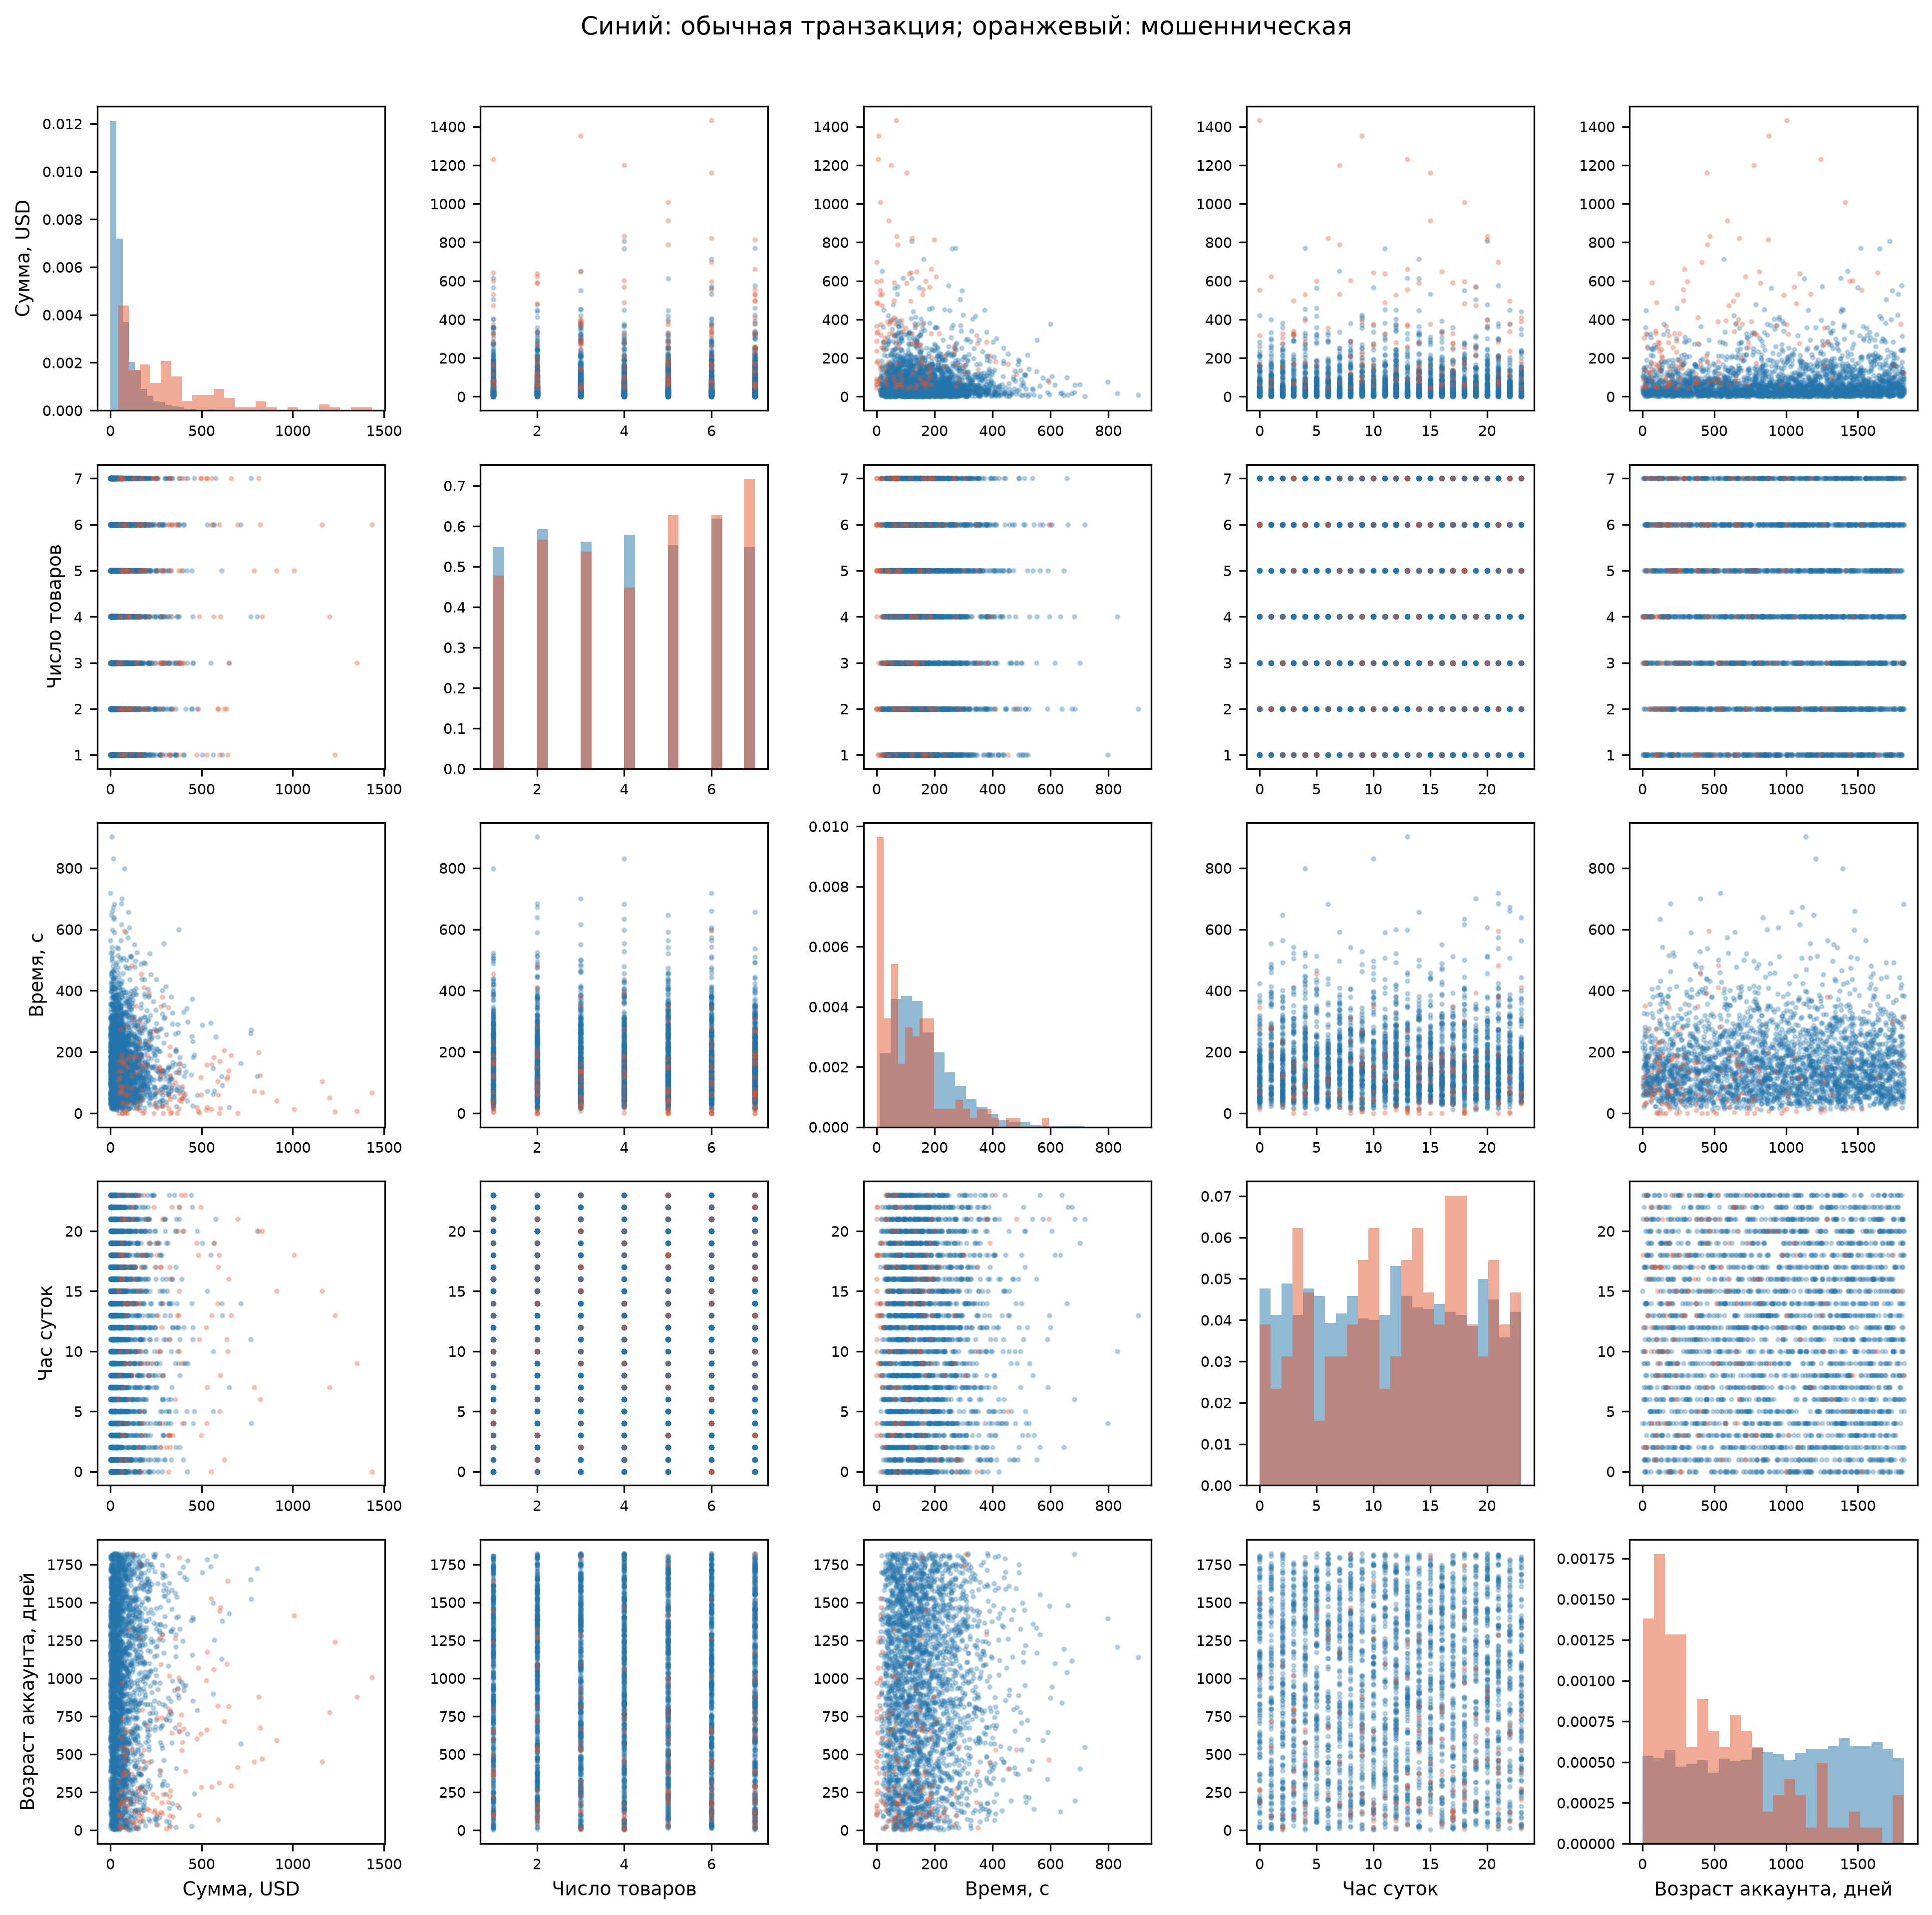

In [5]:
results = json.loads((OUT / 'results.json').read_text())
display(pd.DataFrame({'проверка': ['Исходные строки', 'Отрицательная сумма', 'Отрицательное время', 'Пересечение причин', 'Исключено строк', 'После очистки'], 'количество': [results['raw_rows'], results['negative_amount_rows'], results['negative_time_rows'], results['negative_amount_and_time_rows'], results['invalid_rows'], results['clean_rows']]}))
display(pd.read_csv(OUT / 'descriptive_statistics.csv', index_col=0))
display(Image(filename=str(OUT / 'scatter_matrix.png')))

## Подбор числа кластеров

Для KMeans и метода Уорда проверяются k от 2 до 10. Основной критерий выбора: максимальный силуэт в данном диапазоне. Дополнительно рассматриваются локоть KMeans и расстояния последних слияний дендрограммы. Внешние метрики вычисляются после обучения; выбор k не использует Fraud. Дендрограмма рассчитана на всех очищенных строках, для читаемости отображаются последние 20 групп.

,method,k,silhouette,calinski_harabasz,davies_bouldin,ARI,AMI,FMI,homogeneity,completeness,V_measure,inertia
0,KMeans,2,0.166917,515.878705,2.174801,0.000131,0.001082,0.674820,0.003455,0.000940,0.001478,12162.332910
1,KMeans,3,0.178019,505.524896,1.791817,0.057829,0.081983,0.657462,0.237014,0.050001,0.082581,10608.986673
2,KMeans,4,0.183194,531.940204,1.594112,0.034538,0.063071,0.563764,0.237220,0.036841,0.063777,9217.570691
3,KMeans,5,0.183404,551.105399,1.412642,0.017655,0.052026,0.483384,0.233976,0.029775,0.052827,8109.948883
4,KMeans,6,0.191482,561.547004,1.335683,0.014899,0.042092,0.431432,0.215211,0.023878,0.042987,7246.177729
5,KMeans,7,0.188024,552.749578,1.268205,0.011324,0.039334,0.392914,0.220700,0.022186,0.040320,6648.445152
6,KMeans,8,0.193159,541.895222,1.225791,0.008782,0.034928,0.360267,0.211758,0.019675,0.036005,6171.016054
7,KMeans,9,0.186371,522.306583,1.266134,0.007059,0.033542,0.337263,0.215694,0.018873,0.034710,5832.179287
8,KMeans,10,0.184597,507.402057,1.275151,0.008374,0.040375,0.332373,0.265014,0.022610,0.041666,5526.202794
9,Ward,2,0.143995,396.905221,2.494804,0.016806,0.049270,0.682441,0.115744,0.031602,0.049648,NaN


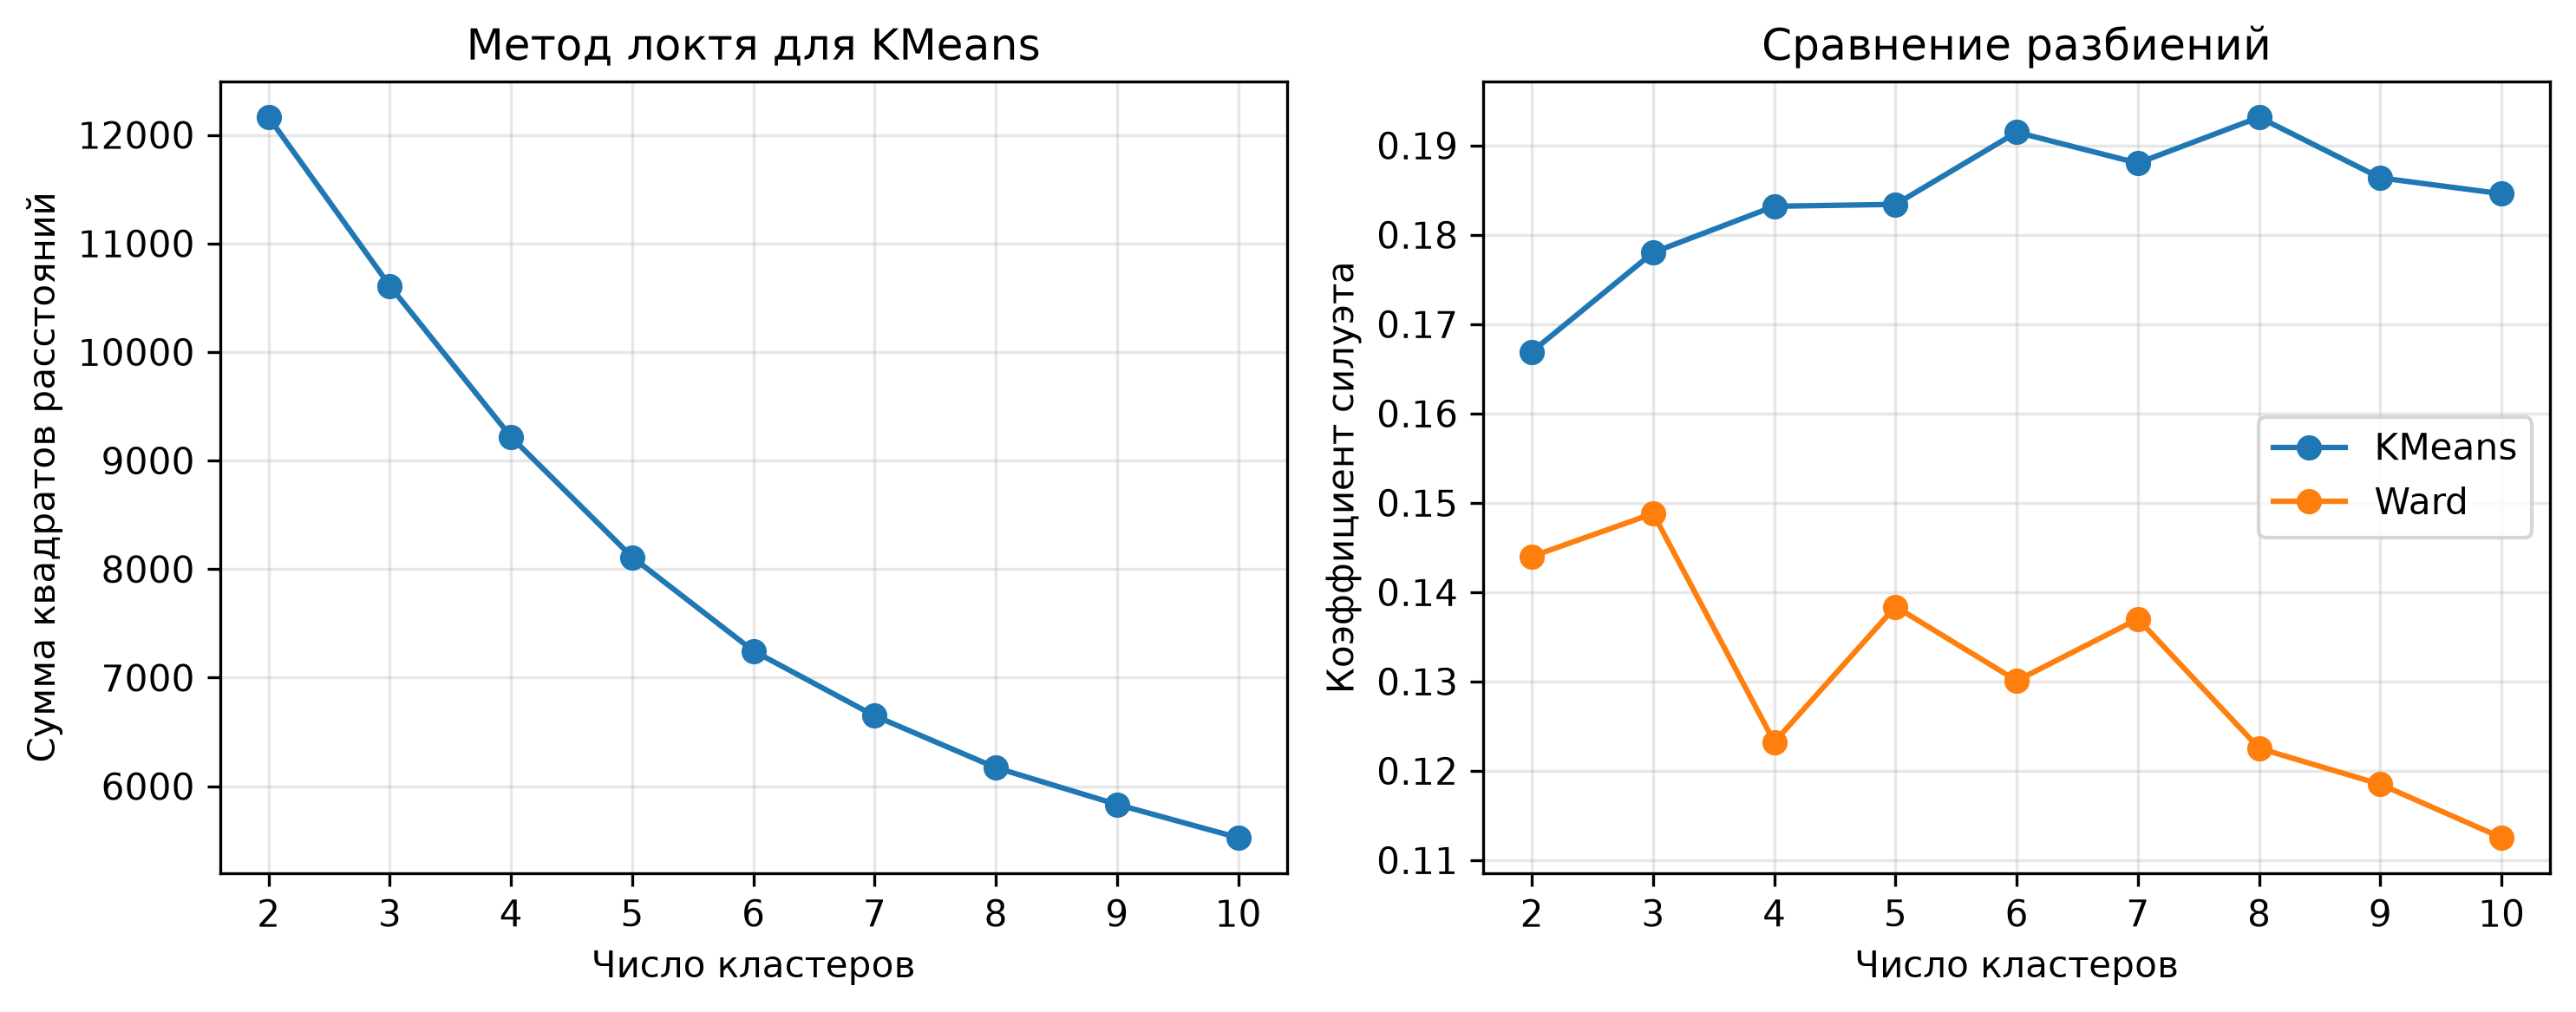

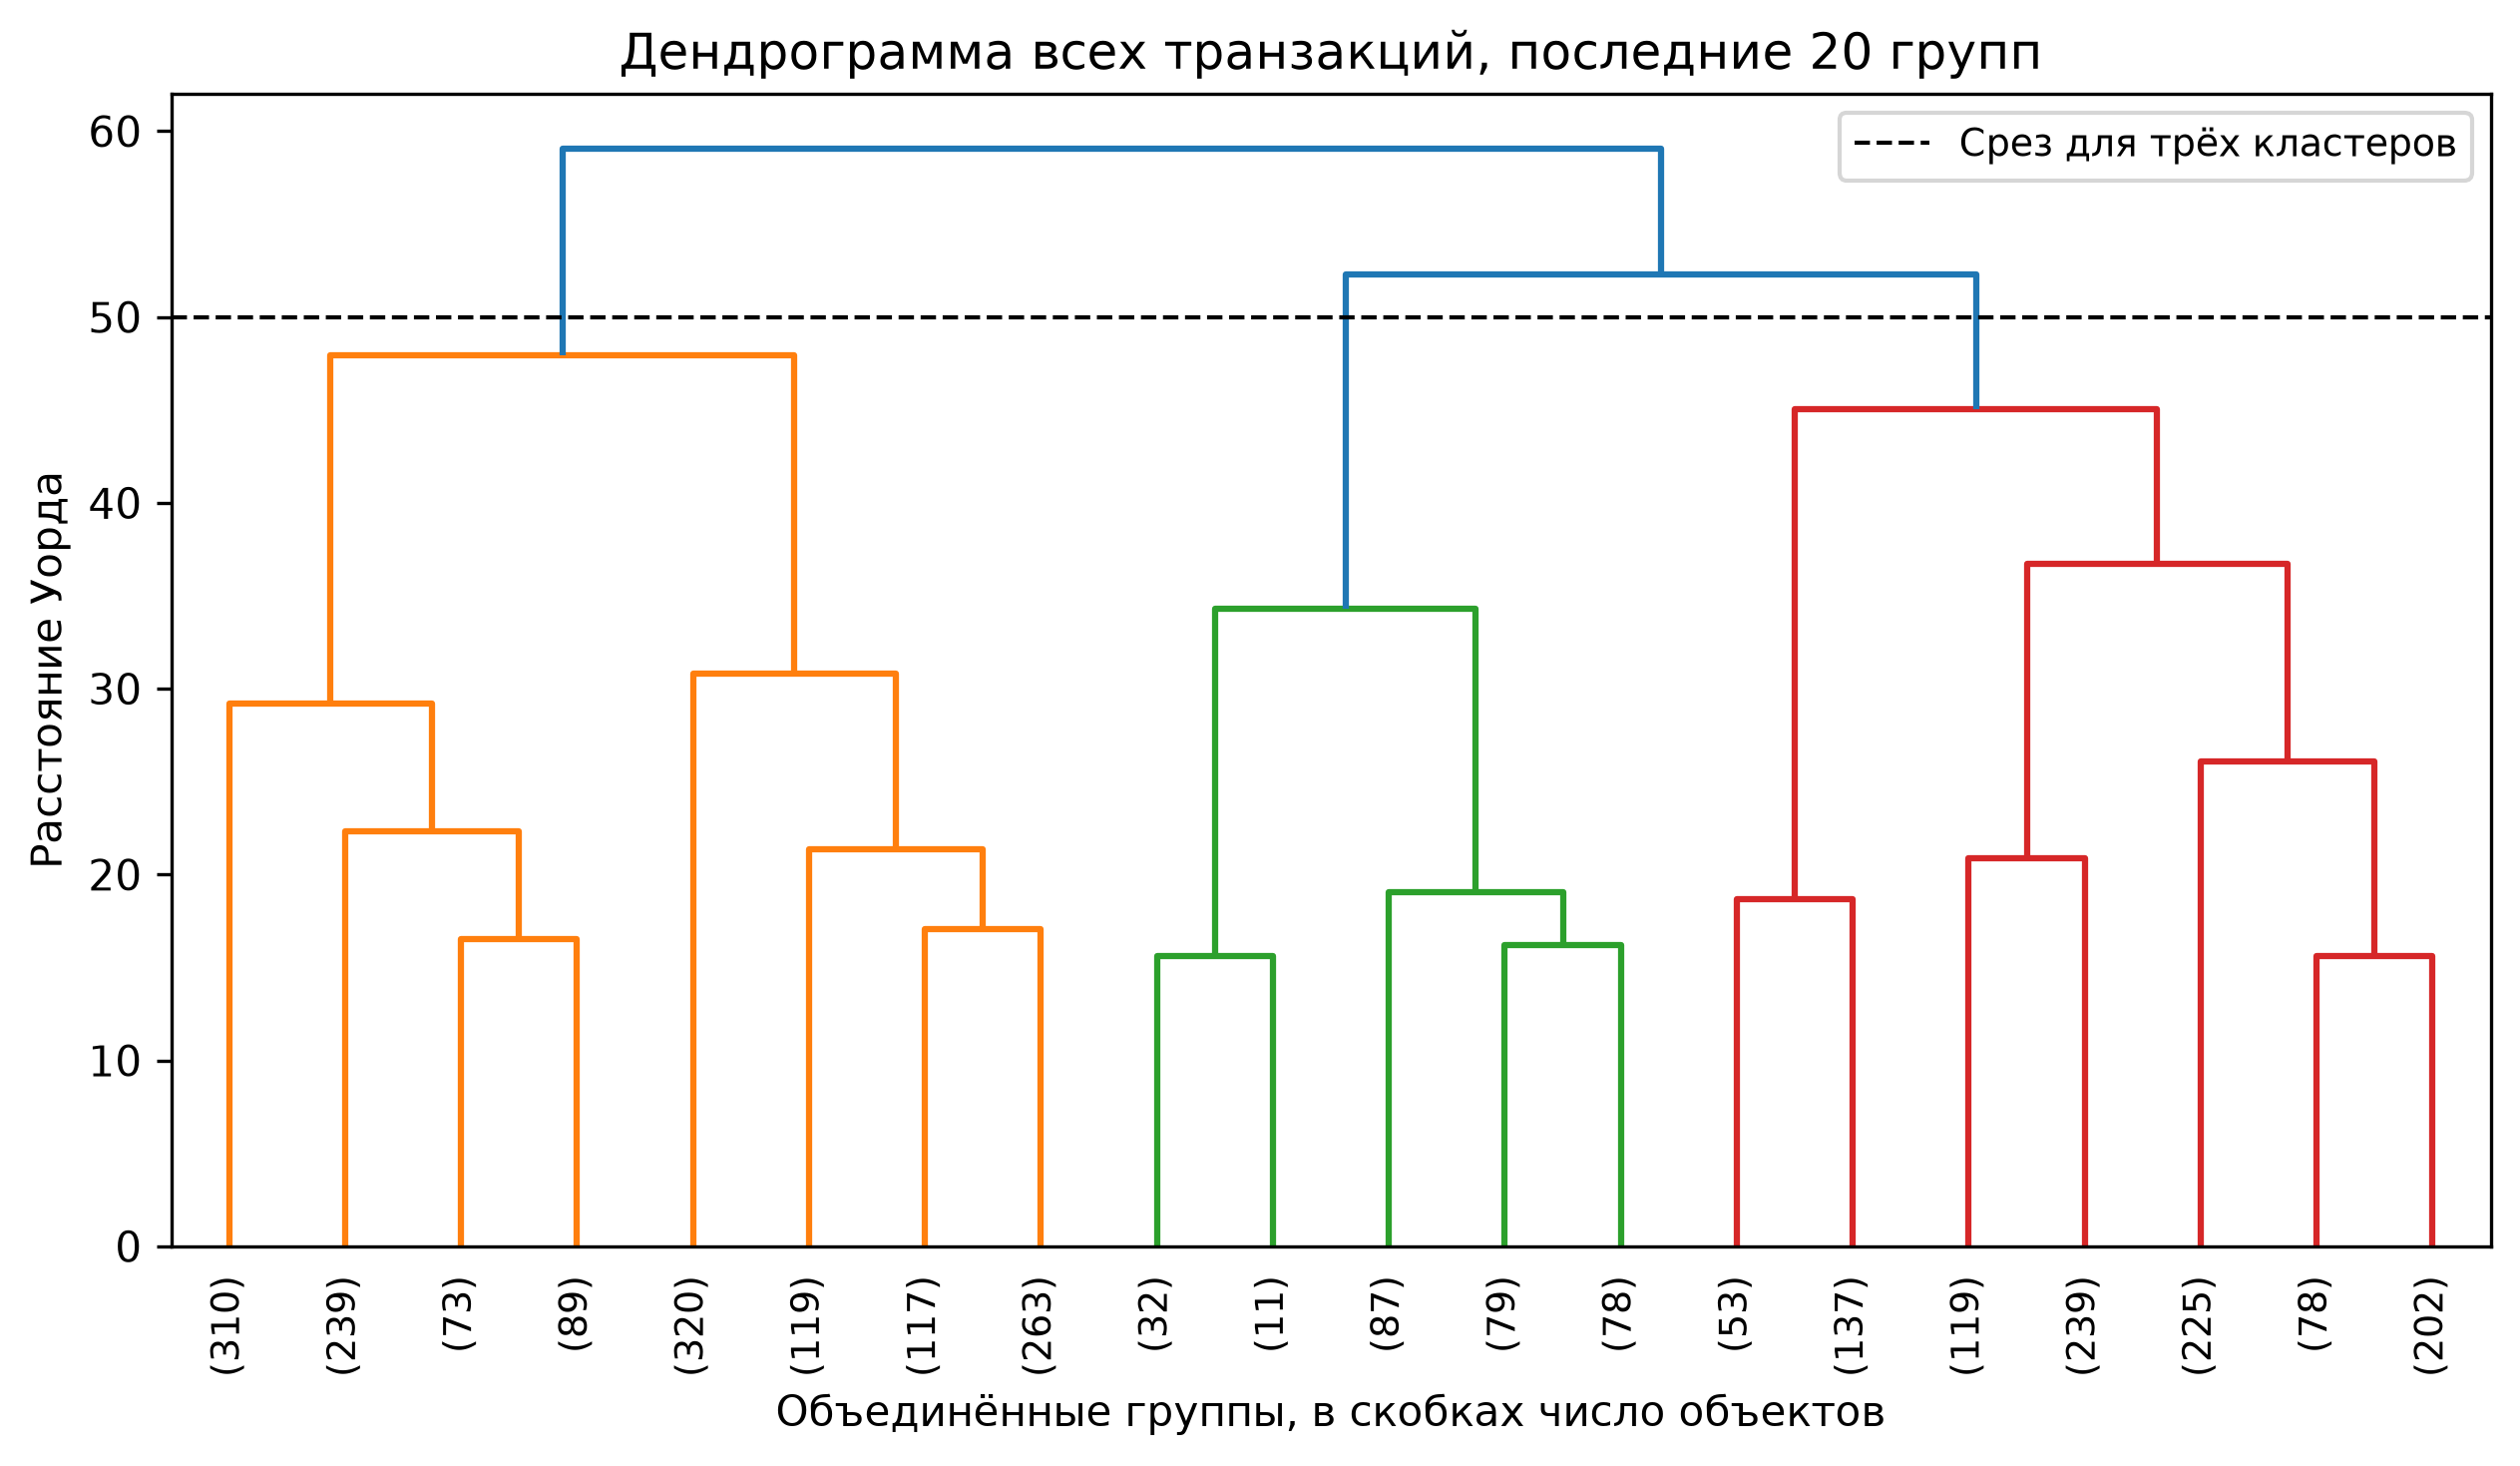

,left,right,distance,size
0,5696.0,5719.0,20.888738,358.0
1,5699.0,5724.0,21.387340,499.0
2,5710.0,5723.0,22.304998,401.0
3,5709.0,5720.0,26.102900,505.0
4,5716.0,5729.0,29.193252,711.0
5,5717.0,5728.0,30.808241,819.0
6,5721.0,5726.0,34.310060,287.0
7,5727.0,5730.0,36.698541,863.0
8,5725.0,5734.0,45.039873,1053.0
9,5731.0,5732.0,47.930089,1530.0


In [6]:
selection = pd.read_csv(OUT / 'model_selection.csv')
display(selection.round(6))
display(Image(filename=str(OUT / 'model_selection.png')))
display(Image(filename=str(OUT / 'dendrogram.png')))
display(pd.read_csv(OUT / 'ward_last_merges.csv'))

## Состав и средние характеристики групп

Номер кластера не является меткой мошенничества. Для каждого метода приведены численность и средние всех числовых признаков в исходных единицах; среднее Fraud равно доле мошеннических транзакций. Матрицы сопряжённости показывают количество обычных и мошеннических операций. Категории представлены долями, поскольку арифметическое среднее строковых значений не определено. Каждая исходная строка получает метку обоих выбранных разбиений.

KMeans делит основные покупки на группы по числу товаров, времени оформления и возрасту аккаунта. Кластер 0 содержит вечерние покупки с большим числом товаров и молодыми аккаунтами; кластер 1 отличается небольшим заказом, ранним часом и старыми аккаунтами. Кластер 2 объединяет вечерние крупные по числу товаров заказы старых аккаунтов, а кластер 3 содержит заказы с большим числом товаров в ранние часы. Кластер 4 объединяет небольшие утренние заказы молодых аккаунтов. Кластер 5 выделяется высокой средней суммой, кластер 6 объединяет небольшие вечерние заказы, кластер 7 отличается длительным временем на сайте.

Метод Уорда даёт более крупные сегменты. В кластере 0 находятся преимущественно старые аккаунты, в кластере 1 возраст аккаунта заметно меньше, а в кластере 2 повышена средняя сумма транзакции. Доли мошенничества различаются, но в каждом из выбранных кластеров присутствуют обычные покупки.

In [7]:
for method in ['kmeans', 'ward']:
    print(method)
    display(pd.read_csv(OUT / f'{method}_profiles.csv').round(5))
    display(pd.read_csv(OUT / f'{method}_target_counts.csv'))
    display(pd.read_csv(OUT / f'{method}_category_shares.csv').pivot(index=['feature', 'category'], columns='cluster', values='share').fillna(0).round(4))
display(pd.read_csv(OUT / 'cluster_assignments.csv').head(10))

kmeans


,cluster,size,transaction_amount,num_items,time_on_site_sec,hour_of_day,account_age_days,Fraud
0,0,415,71.98499,5.52289,133.07952,16.09398,372.20964,0.08193
1,1,427,66.07157,2.62061,146.54333,5.40047,1420.42623,0.00703
2,2,397,65.92542,5.80353,150.33753,16.38035,1411.81612,0.00756
3,3,394,63.80546,5.88579,129.55330,4.12690,873.47462,0.02030
4,4,395,61.36547,2.32152,140.67848,7.32911,366.23291,0.05570
5,5,122,494.58754,3.99180,116.54918,12.21311,996.95902,0.40984
6,6,444,68.85872,2.14414,143.16892,18.35586,1075.31081,0.01126
7,7,276,70.20214,4.17029,405.03986,11.13768,857.18841,0.03261


,row_0,0,1
0,0,381,34
1,1,424,3
2,2,394,3
3,3,386,8
4,4,373,22
5,5,72,50
6,6,439,5
7,7,267,9


cluster                              0       1       2       3       4  \
feature           category                                               
browser           Chrome        0.4771  0.4988  0.4912  0.5025  0.4633   
                  Edge          0.1108  0.1030  0.0982  0.1294  0.1190   
                  Firefox       0.1349  0.1475  0.1486  0.1421  0.1696   
                  Other         0.0675  0.0375  0.0353  0.0457  0.0430   
                  Safari        0.2096  0.2131  0.2267  0.1802  0.2051   
country           BR            0.0867  0.1101  0.0932  0.0964  0.1190   
                  CN            0.0916  0.0773  0.0882  0.0914  0.0835   
                  DE            0.0771  0.0773  0.0756  0.0838  0.0734   
                  FR            0.0771  0.0632  0.0756  0.0558  0.0937   
                  IN            0.1325  0.1358  0.0957  0.1345  0.1165   
                  Other         0.1325  0.1124  0.1108  0.0761  0.0886   
                  UK            0.0940  0.1124  0.1058  0.1497  0.0785   
                  US            0.3084  0.3115  0.3552  0.3122  0.3468   
device_type       Desktop       0.4651  0.4848  0.4081  0.4797  0.4253   
                  Mobile        0.4627  0.4496  0.5038  0.4797  0.4734   
                  Tablet        0.0723  0.0656  0.0882  0.0406  0.1013   
is_first_purchase No            0.5831  0.5574  0.5894  0.6117  0.5823   
                  Yes           0.4169  0.4426  0.4106  0.3883  0.4177   
payment_method    BankTransfer  0.0651  0.0445  0.0605  0.0736  0.0633   
                  COD           0.0530  0.0515  0.0403  0.0482  0.0506   
                  Card          0.6120  0.6183  0.5995  0.5939  0.6101   
                  PayPal        0.2699  0.2857  0.2997  0.2843  0.2759   
referral          Ads           0.1036  0.1194  0.0907  0.1142  0.0911   
                  Direct        0.2723  0.3232  0.3023  0.3020  0.2633   
                  Search        0.4747  0.4145  0.4383  0.4467  0.4354   
                  Social        0.1494  0.1429  0.1688  0.1371  0.2101   

cluster                              5       6       7  
feature           category                              
browser           Chrome        0.4508  0.5293  0.4964  
                  Edge          0.1230  0.0788  0.1014  
                  Firefox       0.2131  0.1577  0.1558  
                  Other         0.0410  0.0518  0.0471  
                  Safari        0.1721  0.1824  0.1993  
country           BR            0.0984  0.0856  0.0870  
                  CN            0.0738  0.1126  0.1196  
                  DE            0.0410  0.0968  0.0942  
                  FR            0.0820  0.0946  0.0942  
                  IN            0.1148  0.1014  0.0942  
                  Other         0.0984  0.0878  0.0978  
                  UK            0.1230  0.0968  0.1159  
                  US            0.3689  0.3243  0.2971  
device_type       Desktop       0.4672  0.4572  0.4203  
                  Mobile        0.4508  0.4730  0.4746  
                  Tablet        0.0820  0.0698  0.1051  
is_first_purchase No            0.5984  0.6036  0.5978  
                  Yes           0.4016  0.3964  0.4022  
payment_method    BankTransfer  0.0574  0.0698  0.0652  
                  COD           0.0410  0.0495  0.0435  
                  Card          0.5902  0.6036  0.6159  
                  PayPal        0.3115  0.2770  0.2754  
referral          Ads           0.0984  0.0991  0.0942  
                  Direct        0.3279  0.3041  0.2862  
                  Search        0.4098  0.4234  0.4601  
                  Social        0.1639  0.1734  0.1594

ward


,cluster,size,transaction_amount,num_items,time_on_site_sec,hour_of_day,account_age_days,Fraud
0,0,1530,65.21512,3.77124,152.30588,11.74771,1286.25163,0.00784
1,1,1053,47.75809,4.33618,188.43400,10.88509,454.78917,0.03894
2,2,287,327.03056,4.19861,147.12892,11.45296,693.67247,0.28223


,row_0,0,1
0,0,1518,12
1,1,1012,41
2,2,206,81


cluster                              0       1       2
feature           category                            
browser           Chrome        0.5046  0.4881  0.4460
                  Edge          0.0974  0.1197  0.1045
                  Firefox       0.1444  0.1519  0.2056
                  Other         0.0444  0.0513  0.0418
                  Safari        0.2092  0.1890  0.2021
country           BR            0.0961  0.1016  0.0871
                  CN            0.0876  0.1073  0.0697
                  DE            0.0804  0.0845  0.0662
                  FR            0.0784  0.0807  0.0732
                  IN            0.1144  0.1216  0.1115
                  Other         0.1059  0.0988  0.0836
                  UK            0.1085  0.0997  0.1324
                  US            0.3288  0.3058  0.3763
device_type       Desktop       0.4562  0.4406  0.4634
                  Mobile        0.4680  0.4834  0.4564
                  Tablet        0.0758  0.0760  0.0801
is_first_purchase No            0.5856  0.5973  0.5784
                  Yes           0.4144  0.4027  0.4216
payment_method    BankTransfer  0.0647  0.0646  0.0453
                  COD           0.0503  0.0465  0.0418
                  Card          0.6065  0.6059  0.6098
                  PayPal        0.2784  0.2830  0.3031
referral          Ads           0.1046  0.0959  0.1115
                  Direct        0.3111  0.2716  0.2997
                  Search        0.4288  0.4568  0.4321
                  Social        0.1556  0.1757  0.1568

,source_row,transaction_amount,device_type,browser,payment_method,country,num_items,time_on_site_sec,is_first_purchase,referral,hour_of_day,account_age_days,Fraud,cluster_KMeans,cluster_Ward
0,0,62.18,Desktop,Safari,COD,UK,3,58.0,No,Direct,15,808,0,6,0
1,1,28.16,Desktop,Chrome,COD,US,2,75.0,Yes,Direct,10,753,0,4,0
2,2,17.57,Mobile,Chrome,Card,DE,1,101.0,No,Social,21,1017,0,6,0
3,3,61.61,Desktop,Safari,PayPal,Other,4,63.0,Yes,Search,20,1146,0,6,0
4,4,4.28,Desktop,Edge,Card,BR,7,399.0,No,Direct,4,1134,0,7,1
5,5,1.85,Desktop,Firefox,Card,IN,5,307.0,Yes,Search,23,674,0,0,1
6,6,12.50,Mobile,Chrome,PayPal,US,4,381.0,No,Search,2,1712,0,7,0
7,7,35.30,Desktop,Safari,Card,IN,3,98.0,No,Search,6,1370,0,1,0
8,8,81.59,Mobile,Firefox,Card,FR,1,257.0,Yes,Direct,17,1574,0,6,0
9,9,46.25,Mobile,Chrome,BankTransfer,IN,5,137.0,No,Search,3,224,0,3,1


## Выводы

На синтетических данных разбиение на три кластера даёт силуэт 0,68698, тогда как два и четыре кластера дают 0,47907 и 0,55549. Локоть также находится около трёх кластеров. Стандартизация устраняет исходное различие масштабов x и y.

Для транзакций исключены 130 строк с отрицательной суммой и 24 с отрицательной длительностью; пересечения нет. После очистки осталось 2870 строк, среди них 134 мошеннические транзакции. По максимальному силуэту в диапазоне 2–10 выбраны KMeans с восемью кластерами и метод Уорда с тремя. Локоть транзакций выражен слабо; переход KMeans от шести к восьми группам повышает силуэт лишь с 0,19148 до 0,19316. Дендрограмма допускает несколько разумных уровней среза: последние расстояния слияния 47,93, 52,28 и 59,07 не показывают резкой границы именно для трёх кластеров. Поэтому выбранное число групп зависит от критерия.

Для подробной сегментации по числовым признакам целесообразен KMeans: его выбранное разбиение имеет больший силуэт и меньший индекс Дэвиса–Болдина. Группа 5 KMeans объединяет 122 транзакции со средней суммой 494,59 USD и долей Fraud 40,98%; группа 7 выделяется длительностью сессии 405,04 с. Метод Уорда даёт более крупные группы, а его группа 2 содержит 287 транзакций с долей Fraud 28,22%. Низкие ARI и AMI обоих разбиений показывают, что сегментация не воспроизводит классы мошенничества. Высокие суммы связаны с повышенной долей Fraud, однако самостоятельным решением для выявления мошенничества эти модели не являются.

## Воспроизведение

Требуются Python 3 и пакеты numpy, pandas, scipy, scikit-learn, matplotlib, nbformat, nbclient, ipykernel. Ноутбук запускается из каталога с analysis.py и подпапкой input. Код не обращается к личным каталогам и не использует сеть. Выходные таблицы и рисунки создаются в output. Исходная таблица транзакций предоставлена вместе с заданием.

Источники: методические указания «Лабораторная работа 4. Кластеризация 2026», страницы 17–23; предоставленный набор данных варианта 3.